In [1]:
import numpy as np
from typing import Dict
import matplotlib.pyplot as plt
from aiexperiments.constants import AsyncTorchMode, StopOnOutputNetworkExtension
from aiexperiments.visualizing.recording.recorder import Recorder
from aiexperiments.visualizing.results import load_experiments_per_series
from aiexperiments.constants import network_extensions_from_string, get_network_extension_from_list, EventOrderingMethod, RefractoryDropoutNetworkExtension, SyncThresholdNetworkExtension, AsyncTorchNetworkExtension, SpikeSparsityLossNetworkExtension, BarrierLIFNetworkExtension, MomentumNoiseNetworkExtension, NoRefracNetworkExtension
import pandas as pd
from matplotlib.ticker import ScalarFormatter,FormatStrFormatter


def series_to_label(series):
    if series == 'shd':
        return 'SHD'
    elif series == 'nmnist':
        return 'N-MNIST'
    elif series == 'dvsgesture':
        return 'DVS gesture'
    else:
        return series
    
def mode_to_label(mode):
    if mode == AsyncTorchMode.RANDOM:
        return 'RS'
    elif mode == AsyncTorchMode.MEMBRANE_POTENTIAL:
        return 'MS'
    else:
        return mode

Idea: put all hyperparam figures in a single plot, with three sub-plots (F, momentum noise, refractory dropout). Lines for NMNIST and SHD, both MS and RS.

### Check

In [11]:
series = 'nmnist'
experiments_per_series = {series: [1]}
results = load_experiments_per_series(experiments_per_series)[series]
for key in results.spike_counts.keys():
    print(key.inference_nn_extensions)
    print(results.accuracies[key])

Loading results...


100%|██████████| 1/1 [00:00<00:00,  5.90it/s]

async_torch/1/random,log_spike_dynamics,stop_on_output/8
0.3085
async_torch/8/random,log_spike_dynamics,stop_on_output/1
0.6246
async_torch/64/random,log_spike_dynamics
0.9489


## Variable stop conditions

In [2]:
experiments_per_series = {'nmnist': [26,27,28], 'shd': [26,27,28], 'dvsgesture': [26,27,28]}
results_per_series = load_experiments_per_series(experiments_per_series)

Loading results...


100%|██████████| 3/3 [00:01<00:00,  1.82it/s]


Loading results...


100%|██████████| 3/3 [00:01<00:00,  1.67it/s]


Loading results...


100%|██████████| 3/3 [00:01<00:00,  2.80it/s]


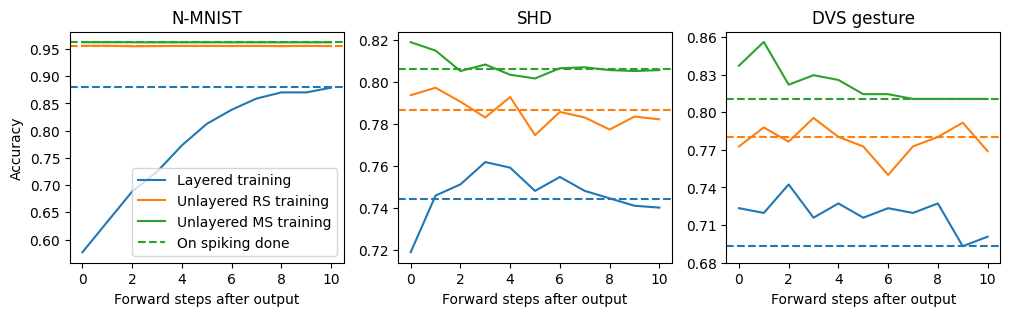

In [80]:
plot_F_inference = 8
plot_max_post_output_steps = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, None]
plot_F_training_and_inference_mode = [(None, AsyncTorchMode.RANDOM), (8, AsyncTorchMode.RANDOM), (8, AsyncTorchMode.MEMBRANE_POTENTIAL)]
plot_series = ['nmnist', 'shd', 'dvsgesture']
data_entries = np.zeros((len(plot_series), len(plot_F_training_and_inference_mode), len(plot_max_post_output_steps)))

for series, results in results_per_series.items():
    for j, key in enumerate(results.spike_counts.keys()):
        # Gather network extensions
        training_nn_extensions = network_extensions_from_string(key.training_nn_extensions)
        inference_nn_extensions = network_extensions_from_string(key.inference_nn_extensions)
        async_torch_training_extension: AsyncTorchNetworkExtension = get_network_extension_from_list(training_nn_extensions, AsyncTorchNetworkExtension)
        async_torch_inference_extension: AsyncTorchNetworkExtension = get_network_extension_from_list(inference_nn_extensions, AsyncTorchNetworkExtension)
        F_inference = async_torch_inference_extension.forward_group_size
        if F_inference != plot_F_inference:
            continue
        F_training = async_torch_training_extension.forward_group_size if async_torch_training_extension is not None else None
        stop_on_output_extension = get_network_extension_from_list(inference_nn_extensions, StopOnOutputNetworkExtension)
        max_post_output_steps = stop_on_output_extension.max_post_output_steps if stop_on_output_extension is not None else None
        inference_mode = async_torch_inference_extension.mode
        if (F_training, inference_mode) not in plot_F_training_and_inference_mode:
            continue
        data_entries[plot_series.index(series), plot_F_training_and_inference_mode.index((F_training, inference_mode)), plot_max_post_output_steps.index(max_post_output_steps)] = results.accuracies[key]

fig, axs = plt.subplots(1, 3, figsize=(12, 3))
for i, series in enumerate(plot_series):
    axs[i].set_title(series_to_label(series))
    min_accuracy = 1
    max_accuracy = 0
    for j, (F_training, mode) in enumerate(plot_F_training_and_inference_mode):
        color = 'C' + str(j)
        training_mode = f'Unlayered {mode_to_label(mode)} training' if F_training is not None else 'Layered training'
        axs[i].plot(plot_max_post_output_steps[:-1], data_entries[i, j][:-1], label=f'{training_mode}', color=color)
        max_accuracy = max(max_accuracy, data_entries[i, j][:-1].max())
        min_accuracy = min(min_accuracy, data_entries[i, j][:-1].min())
        marker_label = None
        if j == 2:
            marker_label = 'On spiking done'
        y_value = data_entries[i, j][-1]
        axs[i].axhline(y=y_value, color=color, linestyle='--', label=marker_label)
    axs[i].set_xlabel('Forward steps after output')

    if i == 0:
        y_min = 0.6
        y_max = 0.96
        y_step = 0.05
    elif i == 1:
        y_min = 0.72
        y_max = 0.83
        y_step = 0.02
    else:
        y_min = 0.68
        y_max = 0.87
        y_step = 0.03
    axs[i].set_yticks(np.arange(y_min, y_max, y_step))
    #axs[i].set_ylim([min_accuracy - min_accuracy*0.01, ])

axs[0].set_ylabel('Accuracy')
axs[0].legend()
plt.savefig('./figures/max_forward_steps_after_output.png', bbox_inches = 'tight')
plt.show()

## Effect on network dynamics + Sparsity bar plot

Loading results...


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 10.30it/s]


Loading results...


100%|██████████| 1/1 [00:00<00:00,  4.36it/s]


Loading results...


... (3 outputs left out)

Loading results...


100%|██████████| 2/2 [00:00<00:00,  5.49it/s]


Loading results...


100%|██████████| 2/2 [00:00<00:00, 11.10it/s]


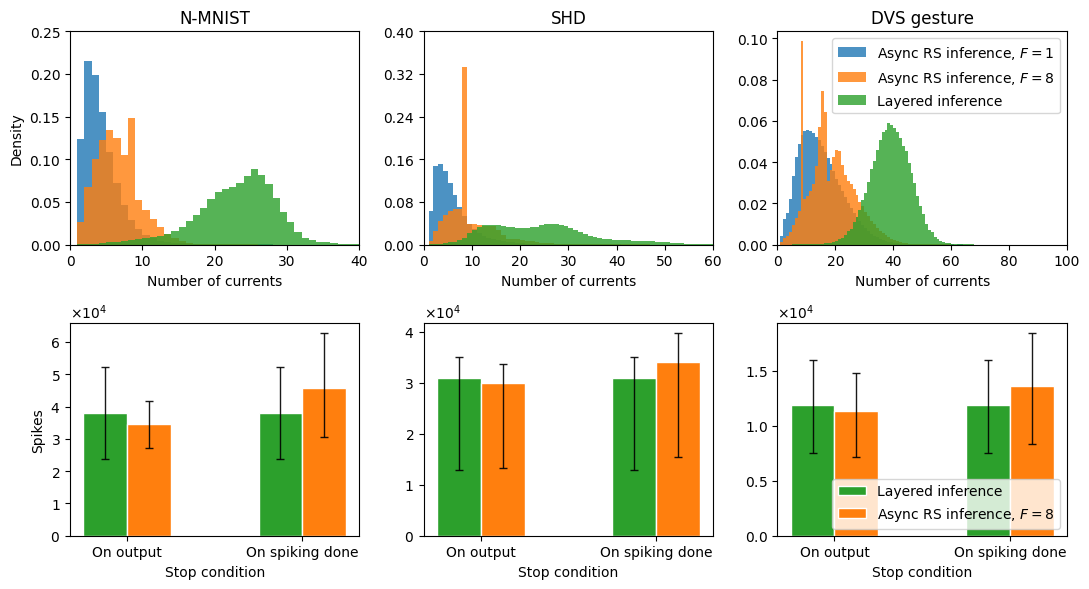

In [7]:
fig, axs = plt.subplots(2, 3, figsize=(11, 6))

# -----------------------------------------------------------
# 1. Effect on network dynamics
experiments_per_series = {'nmnist': [1], 'shd': [1], 'dvsgesture': [1]}
results_per_series = load_experiments_per_series(experiments_per_series)
axs[0,0].set_ylabel('Density')

layer_F = {
    'nmnist': 64,
    'shd': 128,
    'dvsgesture': 128
}
plot_inference_Fs = {
    'nmnist': [1,8,64],
    'shd': [1,8,128],
    'dvsgesture': [1,8,128]
}
range_bins = {
    'nmnist': ((0, 40), 40),
    'shd': ((0, 60), 60),
    'dvsgesture': ((0, 100), 100),
}

for i, (series, results) in enumerate(results_per_series.items()):
    max_n = 0
    for j, key in enumerate(results.spike_counts.keys()):
        training_nn_extensions = network_extensions_from_string(key.training_nn_extensions)
        inference_nn_extensions = network_extensions_from_string(key.inference_nn_extensions)
        async_torch_training_extension: AsyncTorchNetworkExtension = get_network_extension_from_list(training_nn_extensions, AsyncTorchNetworkExtension)
        async_torch_inference_extension: AsyncTorchNetworkExtension = get_network_extension_from_list(inference_nn_extensions, AsyncTorchNetworkExtension)
        F_inference = async_torch_inference_extension.forward_group_size
        if F_inference in plot_inference_Fs[series]:
            label = 'Layered inference' if F_inference == layer_F[series] else f'Async RS inference, $F={F_inference}$'
            n, _, _ = axs[0,i].hist(results.n_currents_to_spike[key], alpha=0.8, label=label, range=range_bins[series][0], bins=range_bins[series][1], color=f'C{j}', density=True)
            max_n = max(max_n, n.max())
    axs[0,i].set_title(series_to_label(series))
    axs[0,i].set_xlabel('Number of currents')
    if i == 2:
        axs[0,i].legend()
    axs[0,i].set_xlim(range_bins[series][0])
    n_step = np.round(max_n / 4, 2)
    axs[0,i].set_yticks(np.arange(0, max_n + n_step, n_step))


# -----------------------------------------------------------
# 2. Spike count
experiments_per_series = {'nmnist': [1,25], 'shd': [1,25], 'dvsgesture': [1,25]}
results_per_series = load_experiments_per_series(experiments_per_series)
plot_F_inference_async = 8
plot_F_training = None # = Layered
barWidth = 0.25

for i, (series, results) in enumerate(results_per_series.items()):
    assert axs[0,i].get_title() == series_to_label(series)
    layered_bars = np.zeros(2) # [On output, On no spikes]
    async_rs_bars = np.zeros(2)
    layered_bars_lower25pct = np.zeros(2)
    async_rs_bars_lower25pct = np.zeros(2) 
    layered_bars_upper25pct = np.zeros(2)
    async_rs_bars_upper25pct = np.zeros(2)
    for j, key in enumerate(results.spike_counts.keys()):
        # Gather network extensions
        training_nn_extensions = network_extensions_from_string(key.training_nn_extensions)
        inference_nn_extensions = network_extensions_from_string(key.inference_nn_extensions)
        async_torch_training_extension: AsyncTorchNetworkExtension = get_network_extension_from_list(training_nn_extensions, AsyncTorchNetworkExtension)
        async_torch_inference_extension: AsyncTorchNetworkExtension = get_network_extension_from_list(inference_nn_extensions, AsyncTorchNetworkExtension)
        F_inference = async_torch_inference_extension.forward_group_size
        if F_inference == 64 or F_inference == 128:
            F_inference = None # = Layered
        F_training = async_torch_training_extension.forward_group_size if async_torch_training_extension is not None else None
        stop_on_output = get_network_extension_from_list(inference_nn_extensions, StopOnOutputNetworkExtension) is not None
        # Plot
        if (F_inference == plot_F_inference_async or F_inference is None) and F_training == plot_F_training:
            modify_bars = layered_bars if F_inference is None else async_rs_bars
            lower_25pct = layered_bars_lower25pct if F_inference is None else async_rs_bars_lower25pct
            upper_25pct = layered_bars_upper25pct if F_inference is None else async_rs_bars_upper25pct
            if stop_on_output:
                modify_bars[0] = results.spike_counts[key].sum(axis=0).mean()
                lower_25pct[0] = np.quantile(results.spike_counts[key].sum(axis=0), 0.25)
                upper_25pct[0] = np.quantile(results.spike_counts[key].sum(axis=0), 0.75)
            else:
                modify_bars[1] = results.spike_counts[key].sum(axis=0).mean()
                lower_25pct[1] = np.quantile(results.spike_counts[key].sum(axis=0), 0.25)
                upper_25pct[1] = np.quantile(results.spike_counts[key].sum(axis=0), 0.75)
    
    r1 = np.arange(barWidth/2, len(layered_bars))
    r2 = [x + barWidth for x in r1]

    capsize = 3  # Size of the horizontal cap ends
    elinewidth = 1  # Width of the error bars
    alpha = 0.9  # Transparency of the error bars

    axs[1,i].bar(r1, layered_bars, width=barWidth, edgecolor='white', label='Layered inference', color='C2')
    axs[1,i].bar(r2, async_rs_bars, width=barWidth, edgecolor='white', label='Async RS inference, $F=8$', color='C1')
    axs[1,i].errorbar(r1, layered_bars, yerr=[layered_bars-layered_bars_lower25pct, layered_bars_upper25pct-layered_bars],
                    fmt='none', color='black', capsize=capsize, elinewidth=elinewidth, alpha=alpha)
    axs[1,i].errorbar(r2, async_rs_bars, yerr=[async_rs_bars-async_rs_bars_lower25pct, async_rs_bars_upper25pct-async_rs_bars],
                    fmt='none', color='black', capsize=capsize, elinewidth=elinewidth, alpha=alpha)

    axs[1,i].set_xlabel('Stop condition')
    axs[1,i].set_xticks([r + barWidth for r in range(len(layered_bars))], ['On output', 'On spiking done'])

    # Set y-axis formatter
    formatter = ScalarFormatter(useMathText=True)
    formatter.set_scientific(True)
    formatter.set_powerlimits((-1,1))
    axs[1,i].yaxis.set_major_formatter(formatter)

axs[1,0].set_ylabel('Spikes')
axs[1,2].legend(loc='lower right')
fig.set_tight_layout(True)
plt.savefig('./figures/network_dynamics_spike_count.png', bbox_inches = 'tight')
plt.show()

## Performance results

In [83]:
experiments_per_series = {'nmnist': [1,2,3], 'shd': [1,2,3], 'dvsgesture': [1,2,3]}
results_per_series = load_experiments_per_series(experiments_per_series)

Loading results...


100%|██████████| 3/3 [00:00<00:00,  8.23it/s]


Loading results...


100%|██████████| 3/3 [00:00<00:00,  5.88it/s]


Loading results...


100%|██████████| 3/3 [00:00<00:00, 11.96it/s]


In [3]:
table = pd.DataFrame(columns=['Training', 'Inference', 'Accuracy nmnist', 'Sparsity nmnist', 'Accuracy shd', 'Sparsity shd'])
plot_mode_training_inference_combos = [
    (AsyncTorchMode.RANDOM, None, None),
    (AsyncTorchMode.RANDOM, None, 8),
    #(AsyncTorchMode.RANDOM, None, 1),
    (AsyncTorchMode.RANDOM, 8, 8),
    #(AsyncTorchMode.RANDOM, 8, 1),
    (AsyncTorchMode.MEMBRANE_POTENTIAL, 8, 8),
    #(AsyncTorchMode.MEMBRANE_POTENTIAL, 8, 1),
]
n_neurons = {
    'shd': 128*3,
    'nmnist': 64*3,
    'dvsgesture': 128*3
}
for i, (mode, F_training, F_inference) in enumerate(plot_mode_training_inference_combos):
    # Generate training mode label
    if F_training is not None:
        training_label = 'Unlayered ' + mode_to_label(mode)
    else:
        training_label = 'Layered'
    # Generate inference mode label
    if F_inference is not None:
        inference_label = f'Async {mode_to_label(mode)}'# ($F={F_inference}$)'
    else:
        inference_label = 'Layered'

    table.loc[i] = [training_label, inference_label, 0.0, 0.0, 0.0, 0.0]


for i, (series, results) in enumerate(results_per_series.items()):
    for j, key in enumerate(results.spike_counts.keys()):
        training_nn_extensions = network_extensions_from_string(key.training_nn_extensions)
        inference_nn_extensions = network_extensions_from_string(key.inference_nn_extensions)
        async_torch_training_extension: AsyncTorchNetworkExtension = get_network_extension_from_list(training_nn_extensions, AsyncTorchNetworkExtension)
        async_torch_inference_extension: AsyncTorchNetworkExtension = get_network_extension_from_list(inference_nn_extensions, AsyncTorchNetworkExtension)
        F_inference = async_torch_inference_extension.forward_group_size
        if F_inference == 64 or F_inference == 128:
            F_inference = None
        F_training = async_torch_training_extension.forward_group_size if async_torch_training_extension is not None else None
        mode = async_torch_inference_extension.mode
        # Get index of the current mode_training_inference_combo
        try:
            index = plot_mode_training_inference_combos.index((mode, F_training, F_inference))
            table.loc[index, f'Accuracy {series}'] = results.accuracies[key]
            table.loc[index, f'Sparsity {series}'] = (results.spike_counts[key].sum(axis=1)/(n_neurons[series])).mean()
        except ValueError:
            pass
            
print(table.to_latex(index=False, float_format="%.3f"))

\begin{tabular}{llrrrrrr}
\toprule
Training & Inference & Accuracy nmnist & Sparsity nmnist & Accuracy shd & Sparsity shd & Accuracy dvsgesture & Sparsity dvsgesture \\
\midrule
Layered & Layered & 0.949 & 3.987 & 0.783 & 14.386 & 0.739 & 46.473 \\
Layered & Async RS & 0.625 & 3.652 & 0.750 & 13.905 & 0.701 & 44.140 \\
Unlayered RS & Async RS & 0.956 & 1.504 & 0.796 & 5.100 & 0.777 & 25.140 \\
Unlayered MS & Async MS & 0.963 & 1.476 & 0.816 & 6.224 & 0.856 & 26.686 \\
\bottomrule
\end{tabular}



## Latency
For SHD and N-MNIST

In [94]:
experiments_per_series = {'nmnist': [1,2,3], 'shd': [1,2,3], 'dvsgesture': [1,2,3]}
results_per_series = load_experiments_per_series(experiments_per_series)

Loading results...


100%|██████████| 3/3 [00:00<00:00,  9.80it/s]


Loading results...


100%|██████████| 3/3 [00:00<00:00, 11.77it/s]


Loading results...


100%|██████████| 3/3 [00:00<00:00, 16.62it/s]


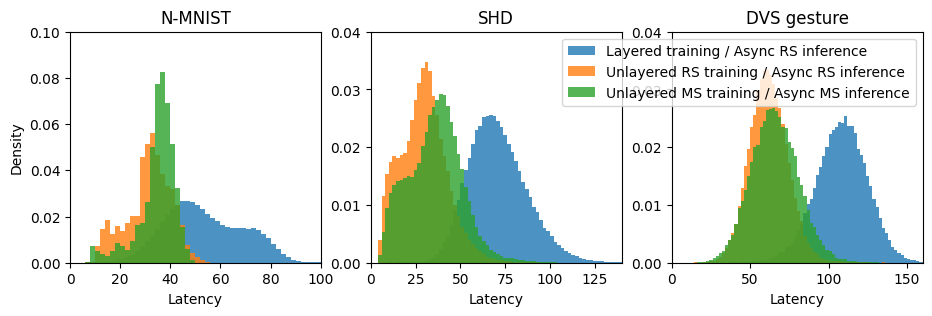

In [95]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3))#, sharey=True)
#fig.suptitle('Distribution of number of spikes in network per forward pass until the first output spike')
axs[0].set_ylabel('Density')
fully_sync_F = {
    'nmnist': 64,
    'shd': 128,
    'dvsgesture': 256
}
plot_training_inference_F = {
    'nmnist': [(8,8,AsyncTorchMode.MEMBRANE_POTENTIAL), (8,8,AsyncTorchMode.RANDOM), (None,8,None)],
    'shd': [(8,8,AsyncTorchMode.MEMBRANE_POTENTIAL), (8,8,AsyncTorchMode.RANDOM), (None,8,None)],
    'dvsgesture': [(8,8,AsyncTorchMode.MEMBRANE_POTENTIAL), (8,8,AsyncTorchMode.RANDOM), (None,8,None)]
}
range_bins = {
    'nmnist': ((0, 100), 50),
    'shd': ((0, 140), 70),
    'dvsgesture': ((0, 160), 80)
}

for i, (series, results) in enumerate(results_per_series.items()):
    max_n = 0
    for key in results.spike_counts.keys():
        training_nn_extensions = network_extensions_from_string(key.training_nn_extensions)
        inference_nn_extensions = network_extensions_from_string(key.inference_nn_extensions)
        async_torch_training_extension: AsyncTorchNetworkExtension = get_network_extension_from_list(training_nn_extensions, AsyncTorchNetworkExtension)
        async_torch_inference_extension: AsyncTorchNetworkExtension = get_network_extension_from_list(inference_nn_extensions, AsyncTorchNetworkExtension)
        F_inference = async_torch_inference_extension.forward_group_size
        F_training = async_torch_training_extension.forward_group_size if async_torch_training_extension is not None else None
        training_mode = async_torch_training_extension.mode if async_torch_training_extension is not None else None
        if (F_training, F_inference, training_mode) in plot_training_inference_F[series]:
            accuracy = results.accuracies[key]
            if async_torch_training_extension is not None:
                if async_torch_training_extension.mode == AsyncTorchMode.MEMBRANE_POTENTIAL and async_torch_training_extension.mode == async_torch_inference_extension.mode:
                    label = f'Unlayered MS training / Async MS inference'
                    color = 'C2'
                else:
                    label = f'Unlayered RS training / Async RS inference'
                    color = 'C1'
            else:
                if F_inference == fully_sync_F:
                    label = f'Layered training / Layered inference'
                    color = 'C5'
                else:
                    label = f'Layered training / Async RS inference'
                    color = 'C0'
            n, _, _ = axs[i].hist(results.classification_latencies[key], alpha=0.8, label=label, range=range_bins[series][0], bins=range_bins[series][1], color=color, density=True)
            max_n = max(max_n, n.max())
    axs[i].set_title(series_to_label(series))
    axs[i].set_xlabel('Latency')
    if i == 2:
        axs[i].legend()
    axs[i].set_xlim(range_bins[series][0])
    n_step = np.round(max_n / 4, 2)
    axs[i].set_yticks(np.arange(0, max_n + n_step, n_step))
#fig.set_tight_layout(True)
plt.savefig('./figures/latency.png', bbox_inches = 'tight')
plt.show()

## Hyperparams
F / Momentum noise / Refractory dropout for SHD and N-MNIST

In [8]:
experiments_per_series_F = {'nmnist': [2,3,17,18,19,20,21,22,23,24], 'shd': [2,3,17,18,19,20,21,22,24], 'dvsgesture': [2,3,17,18,19,20,21,22,24]}
results_F = load_experiments_per_series(experiments_per_series_F)
experiments_per_series_mnoise = {'nmnist': [12,13,14,15,16], 'shd': [3,12,13,14,15,16], 'dvsgesture': [3,12,13,14,15,16]}
results_mnoise = load_experiments_per_series(experiments_per_series_mnoise)
experiments_per_series_refrac = {'nmnist': [2,3,4,5,6,7,8,9,10,11], 'shd': [2,4,5,6,7,3,8,9,10,11], 'dvsgesture': [2,4,5,6,7,3,8,9,10,11]}
results_refrac = load_experiments_per_series(experiments_per_series_refrac)

Loading results...


100%|██████████| 10/10 [00:01<00:00,  9.33it/s]


Loading results...


100%|██████████| 9/9 [00:00<00:00,  9.09it/s]


Loading results...


100%|██████████| 9/9 [00:00<00:00, 13.30it/s]


... (8 outputs left out)

Loading results...


100%|██████████| 10/10 [00:01<00:00,  8.22it/s]


Loading results...


100%|██████████| 10/10 [00:00<00:00, 12.46it/s]


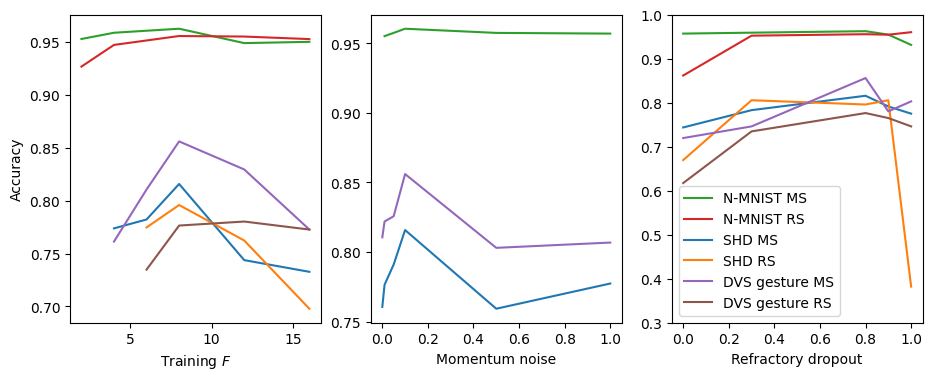

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(11, 4))#, sharey=True)
#fig.suptitle('Effect of hyperparameters on accuracy')
axs[0].set_ylabel('Accuracy')
plot_F_inference = {
    'shd': 8,
    'nmnist': 8,
    'dvsgesture': 8
}

def get_color(series, mode):
    if series == 'shd':
        if mode == AsyncTorchMode.MEMBRANE_POTENTIAL:
            return 'C0'
        else:
            return 'C1'
    elif series == 'nmnist':
        if mode == AsyncTorchMode.MEMBRANE_POTENTIAL:
            return 'C2'
        else:
            return 'C3'
    else:
        if mode == AsyncTorchMode.MEMBRANE_POTENTIAL:
            return 'C4'
        else:
            return 'C5'

# F
min_accuracy = 1
max_accuracy = 0
for series, results in results_F.items():
    xs_per_mode = {AsyncTorchMode.MEMBRANE_POTENTIAL: [], AsyncTorchMode.RANDOM: []}
    ys_per_mode = {AsyncTorchMode.MEMBRANE_POTENTIAL: [], AsyncTorchMode.RANDOM: []}
    for key in results.spike_counts.keys():
        training_nn_extensions = network_extensions_from_string(key.training_nn_extensions)
        inference_nn_extensions = network_extensions_from_string(key.inference_nn_extensions)
        async_torch_training_extension: AsyncTorchNetworkExtension = get_network_extension_from_list(training_nn_extensions, AsyncTorchNetworkExtension)
        async_torch_inference_extension: AsyncTorchNetworkExtension = get_network_extension_from_list(inference_nn_extensions, AsyncTorchNetworkExtension)
        F_inference = async_torch_inference_extension.forward_group_size
        F_training = async_torch_training_extension.forward_group_size
        mode = async_torch_training_extension.mode
        if F_inference == plot_F_inference[series]:
            xs_per_mode[mode].append(F_training)
            ys_per_mode[mode].append(results.accuracies[key])
            max_accuracy = max(max_accuracy, results.accuracies[key])
            min_accuracy = min(min_accuracy, results.accuracies[key])
    for mode in xs_per_mode.keys():
        xs = xs_per_mode[mode]
        ys = ys_per_mode[mode]
        idx = np.argsort(xs)
        xs = np.array(xs)[idx]
        ys = np.array(ys)[idx]
        axs[0].plot(xs, ys, label=f'{series_to_label(series)} {mode_to_label(mode)}', color=get_color(series, mode))
axs[0].set_xlabel('Training $F$')
#axs[0].set_yticks(np.arange(np.round(min_accuracy, 2), np.round(max_accuracy, 2), 0.05))
axs[0].set_yticks(np.arange(0.7, max_accuracy, 0.05))

# Momentum noise
min_accuracy = 1
max_accuracy = 0
for series, results in results_mnoise.items():
    xs = []
    ys = []
    for key in results.spike_counts.keys():
        training_nn_extensions = network_extensions_from_string(key.training_nn_extensions)
        inference_nn_extensions = network_extensions_from_string(key.inference_nn_extensions)
        async_torch_inference_extension: AsyncTorchNetworkExtension = get_network_extension_from_list(inference_nn_extensions, AsyncTorchNetworkExtension)
        F_inference = async_torch_inference_extension.forward_group_size
        momentum_noise_extension: MomentumNoiseNetworkExtension = get_network_extension_from_list(training_nn_extensions, MomentumNoiseNetworkExtension)
        if F_inference == plot_F_inference[series] and momentum_noise_extension is not None:
            xs.append(momentum_noise_extension.lambda_)
            ys.append(results.accuracies[key])
            max_accuracy = max(max_accuracy, results.accuracies[key])
            min_accuracy = min(min_accuracy, results.accuracies[key])
    # sort xs and ys
    idx = np.argsort(xs)
    xs = np.array(xs)[idx]
    ys = np.array(ys)[idx]
    axs[1].plot(xs, ys, label=series_to_label(series), color=get_color(series, AsyncTorchMode.MEMBRANE_POTENTIAL))
axs[1].set_xlabel('Momentum noise')
#axs[1].set_yticks(np.arange(np.round(min_accuracy, 2), np.round(max_accuracy, 2) + 0.05, 0.05))
axs[1].set_yticks(np.arange(0.75, max_accuracy, 0.05))
#axs[1].legend()
# Refractory dropout
min_accuracy = 1
max_accuracy = 0
for series, results in results_refrac.items():
    xs_per_mode = {AsyncTorchMode.MEMBRANE_POTENTIAL: [], AsyncTorchMode.RANDOM: []}
    ys_per_mode = {AsyncTorchMode.MEMBRANE_POTENTIAL: [], AsyncTorchMode.RANDOM: []}
    for key in results.spike_counts.keys():
        training_nn_extensions = network_extensions_from_string(key.training_nn_extensions)
        inference_nn_extensions = network_extensions_from_string(key.inference_nn_extensions)
        async_torch_training_extension: AsyncTorchNetworkExtension = get_network_extension_from_list(training_nn_extensions, AsyncTorchNetworkExtension)
        async_torch_inference_extension: AsyncTorchNetworkExtension = get_network_extension_from_list(inference_nn_extensions, AsyncTorchNetworkExtension)
        F_inference = async_torch_inference_extension.forward_group_size
        refractory_dropout_extension: RefractoryDropoutNetworkExtension = get_network_extension_from_list(training_nn_extensions, RefractoryDropoutNetworkExtension)
        mode = async_torch_training_extension.mode
        if F_inference == plot_F_inference[series] and refractory_dropout_extension is not None:
            xs_per_mode[mode].append(refractory_dropout_extension.dropout)
            ys_per_mode[mode].append(results.accuracies[key])
            max_accuracy = max(max_accuracy, results.accuracies[key])
            min_accuracy = min(min_accuracy, results.accuracies[key])
    for mode in xs_per_mode.keys():
        xs = xs_per_mode[mode]
        ys = ys_per_mode[mode]
        idx = np.argsort(xs)
        xs = np.array(xs)[idx]
        ys = np.array(ys)[idx]
        axs[2].plot(xs, ys, label=f'{series_to_label(series)} {mode_to_label(mode)}', color=get_color(series, mode))
axs[2].set_xlabel('Refractory dropout')
axs[2].legend()
#axs[2].set_yticks(np.arange(np.round(min_accuracy, 2), np.round(max_accuracy, 2) + 0.05, 0.1))
axs[2].set_yticks(np.arange(0.3, 1.1, 0.1))

#fig.set_tight_layout(True)
plt.savefig('./figures/hyperparams.png', bbox_inches = 'tight')
plt.show()

## Static figures

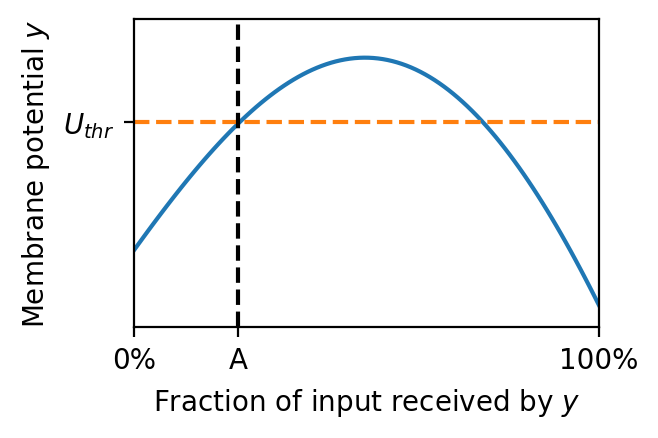

In [101]:
x = np.linspace(0, 2, 100)
y = 0.75 + 0.5 * np.sin(0.4 * np.pi * x) - x*x*0.1
y_threshold = 1
fig, ax = plt.subplots(1, 1, figsize=(3, 2), dpi=200)
ax.plot(x, y, color='C0')
ax.set_xlim(x[0], x[-1])
ax.set_ylim(0.6, 1.2)
ax.plot([x[0],x[-1]], [y_threshold, y_threshold], '--', color='C1')
# plot a X at (2, 1.2) in left plot
#ax.text(0.36, 0.96, 'A', fontsize=18)
#ax.text(1.96, 0.58, 'B', fontsize=18)
ax.xaxis.set_ticks([0, 0.45, 2], ['0%', 'A', '100%'])
# Draw vertical line at x=0.4 and x=2
ax.axvline(x=0.45, color='black', linestyle='--')
#ax.axvline(x=2, color='black', linestyle='--')
ax.yaxis.set_ticks([1], ['$U_{thr}$'])
ax.set_ylabel('Membrane potential $y$')
ax.set_xlabel('Fraction of input received by $y$')
plt.savefig('./figures/async_dynamics.png', bbox_inches = 'tight')
plt.show()